### 1. Construct an SVM model using the data voice.csv

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('voice.csv')

print(df.head())
print(df.shape)
print(df.columns)
print(df['label'].value_counts())

   meanfreq        sd    median       Q25       Q75       IQR       skew  \
0  0.059781  0.064241  0.032027  0.015071  0.090193  0.075122  12.863462   
1  0.066009  0.067310  0.040229  0.019414  0.092666  0.073252  22.423285   
2  0.077316  0.083829  0.036718  0.008701  0.131908  0.123207  30.757155   
3  0.151228  0.072111  0.158011  0.096582  0.207955  0.111374   1.232831   
4  0.135120  0.079146  0.124656  0.078720  0.206045  0.127325   1.101174   

          kurt    sp.ent       sfm  ...  centroid   meanfun    minfun  \
0   274.402906  0.893369  0.491918  ...  0.059781  0.084279  0.015702   
1   634.613855  0.892193  0.513724  ...  0.066009  0.107937  0.015826   
2  1024.927705  0.846389  0.478905  ...  0.077316  0.098706  0.015656   
3     4.177296  0.963322  0.727232  ...  0.151228  0.088965  0.017798   
4     4.333713  0.971955  0.783568  ...  0.135120  0.106398  0.016931   

     maxfun   meandom    mindom    maxdom   dfrange   modindx  label  
0  0.275862  0.007812  0.007812  

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

X = df.drop(columns=['label'])
y = df['label']

In [ ]:
hasil = []

rasio = [0.3, 0.2]  # test_size: 30% dan 20%

kernel_list = ['linear', 'poly', 'rbf']

for test_size in rasio:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    for kernel in kernel_list:
        model = make_pipeline(
            StandardScaler(),
            SVC(kernel=kernel)
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        accuracy = accuracy_score(y_test, y_pred)

        hasil.append({
            'Rasio Split': (
                '70:30' if test_size == 0.3 else '80:20'
            ),
            'Kernel': kernel,
            'Accuracy': accuracy
        })

tabel_hasil = pd.DataFrame(hasil)
print(tabel_hasil)

  Rasio Split  Kernel  Accuracy
0       70:30  linear  0.978970
1       70:30    poly  0.960042
2       70:30     rbf  0.983176
3       80:20  linear  0.974763
4       80:20    poly  0.955836
5       80:20     rbf  0.982650


In [7]:
# show accuracy in pivot table format
tabel_pivot = tabel_hasil.pivot(
    index='Kernel',
    columns='Rasio Split',
    values='Accuracy'
)

print(tabel_pivot)

Rasio Split     70:30     80:20
Kernel                         
linear       0.978970  0.974763
poly         0.960042  0.955836
rbf          0.983176  0.982650


In [4]:
# sort the table by accuracy in descending order
print(
    tabel_hasil.sort_values(
        by='Accuracy',
        ascending=False
    ).reset_index(drop=True)
)

  Rasio Split  Kernel  Accuracy
0       70:30     rbf  0.983176
1       80:20     rbf  0.982650
2       70:30  linear  0.978970
3       80:20  linear  0.974763
4       70:30    poly  0.960042
5       80:20    poly  0.955836


Based on the test results, an SVM model comparison was conducted using linear, polynomial, and RBF kernels, with data split ratios of 70:30 and 80:20. The comparison was based on accuracy values ​​obtained from the testing data. The best model was determined by identifying the combination of kernel and data split ratio that yielded the highest accuracy.

### 2. Day and night image classification using SVM RBF and histogram features

In [9]:
from pathlib import Path
import matplotlib.image as mpimg

train_dir = r"C:\Users\fidelac\OneDrive\Desktop\MachineLearning\JS06\images\training"

def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []

    for folder in p.iterdir():
        if folder.is_dir():
            label = folder.name

            for file in folder.glob("*.jpg"):
                img = mpimg.imread(file)
                img_list.append((img, label))

    return img_list

train_img = load_dataset(train_dir)

print("Jumlah seluruh gambar:", len(train_img))
print("Label gambar:", set(item[1] for item in train_img))

Jumlah seluruh gambar: 240
Label gambar: {'night', 'day'}


In [ ]:
import cv2
import numpy as np

def extract_histogram(image):
    # Konversi RGB ke HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Hitung histogram warna
    hist = cv2.calcHist(
        [img_hsv],
        [0, 1, 2],
        None,
        [8, 8, 8],
        [0, 180, 0, 256, 0, 256]
    )

    # Normalisasi histogram
    hist = cv2.normalize(hist, hist).flatten()

    return hist
X_train_hist = np.array([
    extract_histogram(img) for img in X_train_img
])

X_test_hist = np.array([
    extract_histogram(img) for img in X_test_img
])

print("Shape training:", X_train_hist.shape)
print("Shape testing:", X_test_hist.shape)

Shape training: (192, 512)
Shape testing: (48, 512)


In [13]:
# Train SVM RBF model
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

model_rbf = SVC(kernel='rbf')

model_rbf.fit(X_train_hist, y_train_img)

y_pred_baseline = model_rbf.predict(X_test_hist)

acc_baseline = accuracy_score(
    y_test_img,
    y_pred_baseline
)

print(f'Accuracy SVM RBF: {acc_baseline:.4f}')

# Hyperparameter tuning with GridSearchCV
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.001, 0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    estimator=SVC(kernel='rbf'),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_hist, y_train_img)

print("Parameter terbaik:", grid_search.best_params_)
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")

Accuracy SVM RBF: 1.0000
Parameter terbaik: {'C': 1, 'gamma': 'scale'}
Best CV accuracy: 0.9895


In [14]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test_hist)

acc_tuned = accuracy_score(
    y_test_img,
    y_pred_tuned
)

print(f'Accuracy baseline: {acc_baseline:.4f}')
print(f'Accuracy setelah tuning: {acc_tuned:.4f}')

Accuracy baseline: 1.0000
Accuracy setelah tuning: 1.0000


             Model  Accuracy
0  SVM RBF Default       1.0
1   SVM RBF Tuning       1.0


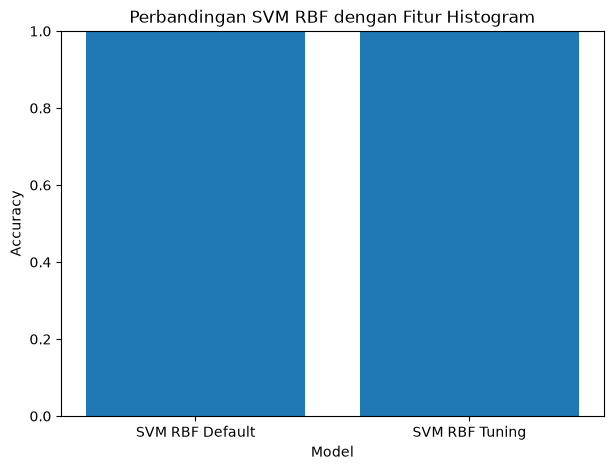

In [15]:
hasil_histogram = pd.DataFrame({
    'Model': [
        'SVM RBF Default',
        'SVM RBF Tuning'
    ],
    'Accuracy': [
        acc_baseline,
        acc_tuned
    ]
})

print(hasil_histogram)

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    hasil_histogram['Model'],
    hasil_histogram['Accuracy']
)

plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('Perbandingan SVM RBF dengan Fitur Histogram')
plt.ylim(0, 1)
plt.show()

An SVM model with an RBF kernel is used to classify daytime and nighttime images based on HSV color histogram features, with an 80:20 data split ratio. Subsequently, the hyperparameters C and gamma are tuned to determine whether the model's performance can be improved. The accuracy results obtained before and after tuning are compared to identify the configuration that yields the best performance on the testing data.